# Relaxed layouts: diagrams that find their own shape

> **In short.**
> * **The problem.** A simplified ZX-diagram has no natural place for its spiders: it no longer has a time axis, and drawn in its two standard columns its structure is hard to see.
> * **The idea (L. Yeh's suggestion).** Give no coordinates at all. Treat the diagram like a molecule, with its edges as bonds, and let a physical model find the shape of lowest energy. Spiders joined by short paths end up close together.
> * **What you see.** The first checks of d = 3 cultivation as a compact, symmetric shape; the double-check as a core with its $T$ gadgets around it, in 2D and 3D; and the whole 311-spider fold-transversal Hadamard, whose layers in time come back from its connections alone.
> * **Codes by their shape.** A code's checks as a diagram (`check_diagram`), relaxed and with each check shaded: the Steane code's three faces (the same picture whatever the qubits' order, and a typo shows at once), the [[8,3,2]] code as a cube, the surface code as a grid of plaquettes, and the [[15,1,3]] code as a tetrahedron cut into four cells.
> * **How to read the pictures.** Green and red dots are Z- and X-spiders, black dots the inputs and outputs. The positions mean nothing beyond which spiders are connected: they are not space or time.
> * New to ZX-diagrams? [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A, explains them with pictures.

A reduced diagram (a normal form) has no positions of its own: `reduce_gpf` lays it out in two columns, Z-spiders on the left and X-spiders on the right, which shows the form but not the structure. Here no coordinates are given at all. The diagram is treated like a molecule: its edges are the bonds, and the layout is where an energy is lowest (`relax_layout`, with `networkx`, `pip install zxqec[layout]`):

* `'kamada-kawai'` (default): a spring between every pair of spiders, whose rest length is their distance in the diagram, and the total energy minimised. Spiders close in the diagram end up close in space.
* `'spring'`: a force simulation in which edges pull and all spiders push each other apart.

The start is random but seeded, so every picture here comes out the same each time. Each connected part is relaxed on its own and the parts are set side by side. The positions mean nothing beyond the connectivity: they are not space or time. `draw_relaxed` draws in 2D with PyZX's own `draw_matplotlib`, `draw_relaxed_3d` in 3D (turn it with the mouse in a window).

In [1]:
import pyzx as zx
from zxqec.qprogram import program_from_stim
from zxqec.gpf import reduce_gpf, phases_modulo
from zxqec.spacetime import draw_relaxed, draw_relaxed_3d
import interactive_fold_h_3d as fth          # picks a window backend when imported ...
%matplotlib inline

p = program_from_stim(open('circuits/cultivation/d3_cultivation.stim').read())[0]

def reduced(g):
    """The normal form of g, outcomes written modulo its detectors."""
    res = reduce_gpf(g)
    return phases_modulo(res.to_graph(), res.detectors)

first_checks = reduced(p.stage_graph(0, classical=False))
double_check = reduced(p.stages_graph(3, 4, classical=False))

## The first checks of d = 3 cultivation

The first stage prepares the Steane code. As reduced, in two columns:

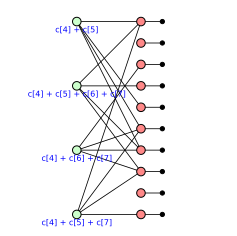

In [2]:
zx.draw_matplotlib(first_checks, figsize=(4, 4))

Relaxed: each of the four Z-spiders (green; a stabilizer of the prepared state, with its outcome parity as its phase) is wired to four qubits and sits among them, and spiders that share qubits pull together into a compact, symmetric shape. The two small parts on the right are qubits not linked to the others.

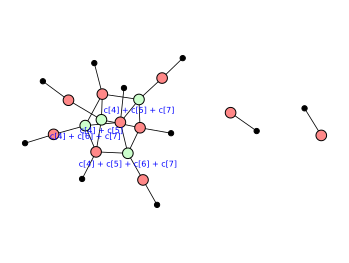

In [3]:
draw_relaxed(first_checks, figsize=(6, 4.5))

## The double-check

The double-check's normal form, 45 spiders: the parity spiders in the middle and the 7π/4 and π/4 gadgets around them. In 2D the core is crowded; in 3D there is room, and in a window it can be turned.

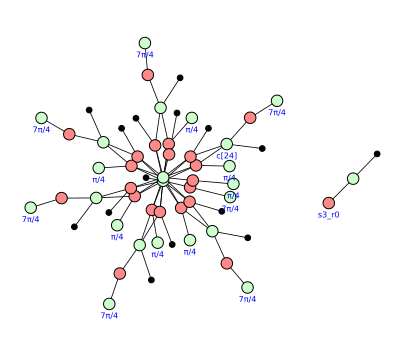

In [4]:
draw_relaxed(double_check, figsize=(7, 6))

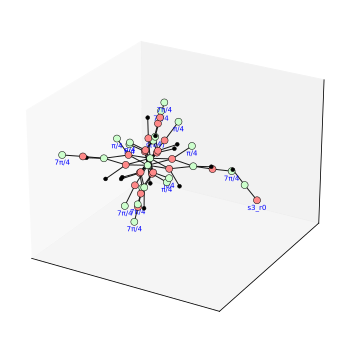

In [5]:
draw_relaxed_3d(double_check, figsize=(7, 6), spider_size=50)

## The whole fold-transversal Hadamard

The method needs nothing but the edges, so it works on any diagram. Here is the whole circuit, 311 spiders, under both energies (half a second each). The force simulation lays it out in sheets: the shape of the program in space and time comes back from its connectivity alone.

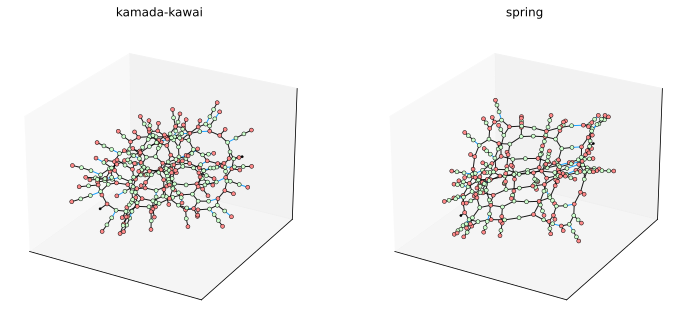

In [6]:
import matplotlib.pyplot as plt
g = fth.build_program().quantum_graph()
fig = plt.figure(figsize=(12, 5.5))
for i, method in enumerate(('kamada-kawai', 'spring')):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    draw_relaxed_3d(g, method=method, ax=ax, show_phases=False, spider_size=16)
    ax.set_title(method)
fig

## Codes by their shape

L. Yeh's uses for these layouts are **debugging**, **recognising the topology** of a code, and routing. A code is usually given by its parity-check matrix, a row per check and a column per qubit. It is hard to read, and it changes when the qubits are numbered differently. The diagram of the checks does not: `check_diagram` gives a spider per check (green for an X-check), joined to a spider on each of its qubits (red, a phase-free X-spider with one output wire). This is the code state in parity normal form (PyZX's `generate_css_encoder_graph`). Relaxed, only the connections decide the picture. Two options help with codes:

* `shade='Z'` colours the qubits of each check (green spider): its face, plaquette or cell;
* `boundaries='outward'` lays out the spiders alone, then points each output wire away from the middle.

### The Steane code

Its three X-checks, and the same code with its seven qubits numbered in another order:

In [7]:
from zxqec.codes import check_diagram, surface_code_checks

steane = [[0, 0, 0, 1, 1, 1, 1],
          [0, 1, 1, 0, 0, 1, 1],
          [1, 0, 1, 0, 1, 0, 1]]
renumbered = [[row[j] for j in (5, 2, 6, 0, 3, 1, 4)] for row in steane]
print("as usual:  ", *steane, sep="\n  ")
print("renumbered:", *renumbered, sep="\n  ")

as usual:  
  [0, 0, 0, 1, 1, 1, 1]
  [0, 1, 1, 0, 0, 1, 1]
  [1, 0, 1, 0, 1, 0, 1]
renumbered:
  [1, 0, 1, 0, 1, 0, 1]
  [1, 1, 1, 0, 0, 1, 0]
  [0, 1, 1, 1, 0, 0, 1]


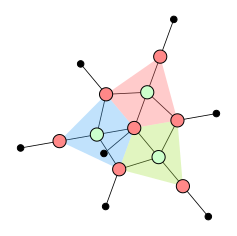

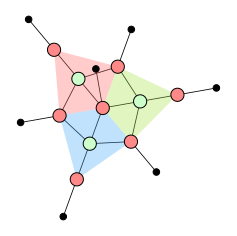

In [8]:
display(draw_relaxed(check_diagram(steane), shade='Z', boundaries='outward', figsize=(4, 4)))
draw_relaxed(check_diagram(renumbered), shade='Z', boundaries='outward', figsize=(4, 4))

Two different matrices, the same picture (turned): the familiar triangle of the Steane code, three faces of four qubits each, with the middle qubit in all three. A wrong entry shows at once. Here the first check also contains qubit 0, a typo; its face spreads over the others:

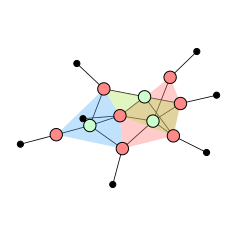

In [9]:
typo = [row[:] for row in steane]
typo[0][0] = 1
draw_relaxed(check_diagram(typo), shade='Z', boundaries='outward', figsize=(4, 4))

### In 3D: the cube

The Steane code's checks are three faces of a cube. Number the corners of a cube by three bits: the three faces that miss the corner $(1,1,1)$, on the other seven corners, are its three checks. The [[8,3,2]] code has all six faces as checks, Z-checks this time (`kind='Z'`: red check spiders, green qubit spiders, shaded with `shade='X'`). Relaxed in 3D, its eight qubits come out on the corners of a cube, and each check sits just outside the middle of its face. Seen from a corner and face on:

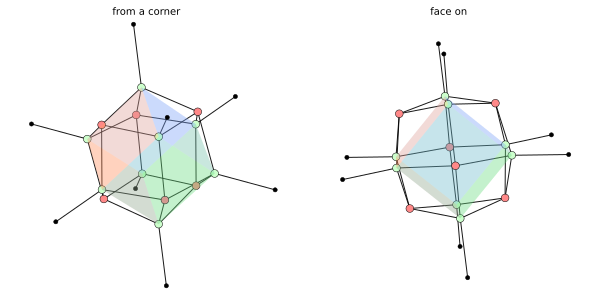

In [10]:
cube_faces = [[1 if ((q >> axis) & 1) == side else 0 for q in range(8)] for axis in range(3) for side in (0, 1)]
draw_relaxed_3d(check_diagram(cube_faces, 'Z'), shade='X', boundaries='outward', box=False,
                views=[(8.4, 82.2), (-22.7, 93.5)], titles=['from a corner', 'face on'], spider_size=60)

`box=False` scales the three directions equally and leaves out the axes box, so that the shape is not stretched; `views` draws the same layout from several sides. The Steane code's three faces alone are not held in shape: in 3D they relax into a slightly puckered copy of the 2D picture, not a cube corner. The energy wants two qubits on different faces twice as far apart as two on one face, whereas on a cube they are only $\sqrt 2$ times as far:

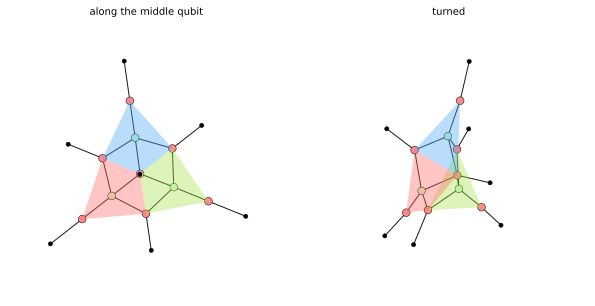

In [11]:
draw_relaxed_3d(check_diagram(steane), shade='Z', boundaries='outward', box=False,
                views=[(-15.1, -17.0), (-8.6, -72.9)], titles=['along the middle qubit', 'turned'], spider_size=60)

### The surface code

`surface_code_checks(d)` gives the X- and Z-checks of the rotated surface code. At distance 5, its X-checks (left) and its Z-checks (right, `kind='Z'`) each relax into a grid of plaquettes, with the two-qubit checks along its edges:

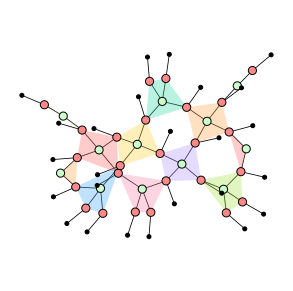

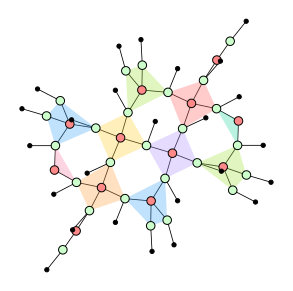

In [12]:
hx, hz = surface_code_checks(5)
display(draw_relaxed(check_diagram(hx), shade='Z', boundaries='outward', figsize=(5, 5)))
draw_relaxed(check_diagram(hz, 'Z'), shade='X', boundaries='outward', figsize=(5, 5))

### The [[15,1,3]] code: a tetrahedron

This is the quantum Reed–Muller code of 15-to-1 magic-state distillation. It has four X-checks of eight qubits each, and column $c$ of its matrix is the number $c$ in binary. In 3D, the four checks and the fifteen qubits, each a phase-free X-spider with one output, take the shape of a tetrahedron cut into four cells, one per check, like L. Yeh's drawing of this code:

* the four qubits in one check sit at the corners;
* the six qubits in two checks sit on the edges;
* the four qubits in three checks sit on the faces;
* the qubit in all four checks sits in the middle.

Seen from a corner, and along the axis through the middles of two opposite edges, where the four cells look like four quarters:

[1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1]
[0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1]
[0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1]
[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]


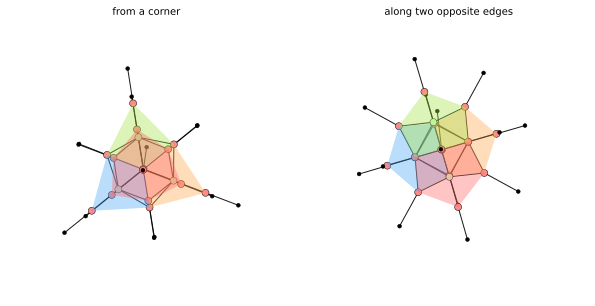

In [13]:
reed_muller = [[(c >> bit) & 1 for c in range(1, 16)] for bit in range(4)]
print(*reed_muller, sep="\n")
draw_relaxed_3d(check_diagram(reed_muller), shade='Z', boundaries='outward', box=False,
                views=[(2.7, -88.5), (56.4, -101.7)], titles=['from a corner', 'along two opposite edges'],
                spider_size=50)

## What this is not

* **Not space or time.** The positions only reflect which spiders are connected; for space and time use `draw_program_3d` or `draw_level_3d`.
* **A local minimum.** The energy is minimised from a seeded random start; another seed can give another layout (a mirror image, or a different local minimum).
* **Not for very large diagrams.** Kamada-Kawai uses the distance between every pair of spiders, so its cost grows with the square of their number; a few hundred spiders take under a second.
* **Views chosen by hand.** The angles in `views` above were picked for these layouts (seed 0); another seed turns the shape, and the angles with it.
